<a href="https://colab.research.google.com/github/DivyaMeenaSundaram/Forensics/blob/main/Copy_move_forgery_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

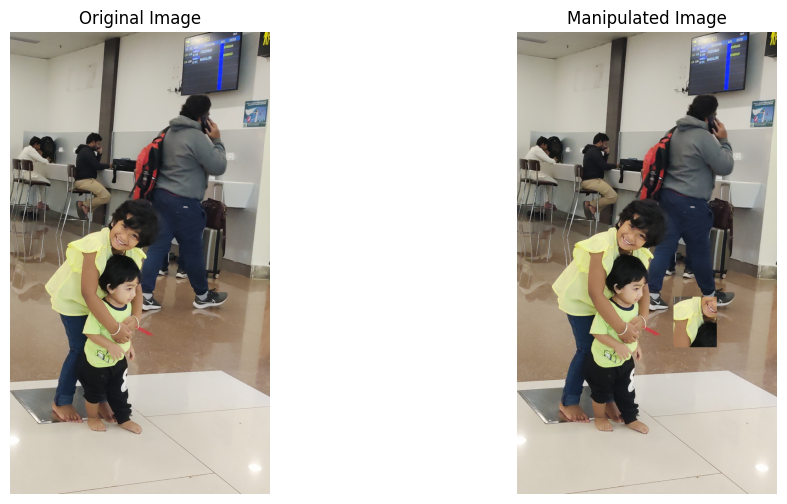

In [9]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use your uploaded original image
original = img.copy()
h, w = original.shape[:2]

# Source region: select a textured area
x1, y1 = 300, 820
x2, y2 = 480, 1030

# Destination: choose a different location
paste_x, paste_y = 650, 1100

patch = original[y1:y2, x1:x2].copy()

ph, pw = patch.shape[:2]

if paste_x + pw > w or paste_y + ph > h:
    raise ValueError("Choose another destination.")

# Create manipulated copy
manipulated = original.copy()

manipulated[
    paste_y:paste_y+ph,
    paste_x:paste_x+pw
] = patch

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(manipulated)
plt.title("Manipulated Image")
plt.axis("off")

plt.show()


Matching score: 1.0
Detected duplicate: (650, 1100)


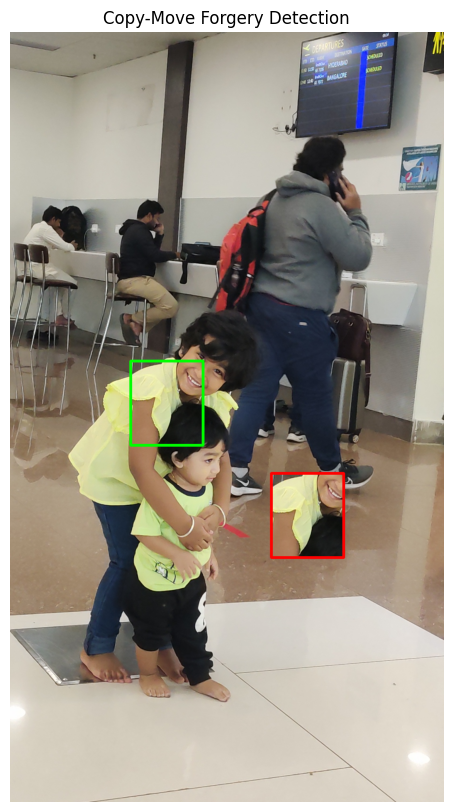

In [10]:

# Convert manipulated image and source patch to grayscale
gray = cv2.cvtColor(manipulated, cv2.COLOR_RGB2GRAY)

template = cv2.cvtColor(patch, cv2.COLOR_RGB2GRAY)

# Template matching
result = cv2.matchTemplate(
    gray,
    template,
    cv2.TM_CCOEFF_NORMED
)

# Exclude the complete original source region
margin = 10

result[
    max(0, y1-margin):min(result.shape[0], y1+margin+1),
    max(0, x1-margin):min(result.shape[1], x1+margin+1)
] = -1

# Find best matching location
_, score, _, location = cv2.minMaxLoc(result)

px, py = location

print("Matching score:", round(score, 4))
print("Detected duplicate:", location)

# Draw bounding boxes
output = manipulated.copy()

# Green = original source
cv2.rectangle(
    output,
    (x1,y1), (x2,y2),
    (0,255,0), 5
)

# Red = detected duplicate
cv2.rectangle(
    output,
    (px,py), (px+pw,py+ph),
    (255,0,0), 5
)

plt.figure(figsize=(9,10))
plt.imshow(output)
plt.title("Copy-Move Forgery Detection")
plt.axis("off")
plt.show()
